# Evaluación de clasificación: diabetes Pima
**Fuente:** https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database  
**Objetivo:** identificar casos positivos minimizando falsos negativos sin ignorar falsas alarmas. Investigación educativa, no dispositivo diagnóstico.

**Reproducibilidad:** ejecutar celdas en orden; semilla fija 42. Colocar `diabetes.csv` de Kaggle junto al notebook; si falta, se intenta descargar una copia pública del mismo dataset. Los resultados se calculan, no se presuponen.

In [1]:
# 1. Dependencias y configuración
# pip install pandas numpy scikit-learn scipy matplotlib seaborn openpyxl
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binomtest
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay)
SEED=42
OUT=Path('resultados_pima'); OUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')

## 2. Dataset y partición
Los ceros en ciertas variables fisiológicas se consideran valores ausentes; se convierten a NaN y se imputan **dentro de cada pipeline**, evitando fuga de información. El conjunto de prueba se reserva antes de ajustar o seleccionar umbrales.

In [2]:
# Preferir archivo original descargado desde Kaggle
source='https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database'
if Path('diabetes.csv').exists():
    df=pd.read_csv('diabetes.csv')
else:
    url='https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
    try:
        df=pd.read_csv(url)
    except Exception as exc:
        raise FileNotFoundError('Descarga diabetes.csv de Kaggle y colócalo junto al notebook.') from exc
assert 'Outcome' in df and len(df)>0
assert set(df['Outcome'].unique()).issubset({0,1})
X=df.drop(columns='Outcome').copy(); y=df['Outcome'].astype(int)
zero_missing=[c for c in ['Glucose','BloodPressure','SkinThickness','Insulin','BMI'] if c in X]
X[zero_missing]=X[zero_missing].replace(0,np.nan)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=SEED)
print('Total:',len(df),'Train:',len(y_train),'Test:',len(y_test),'Positivos:',int(y.sum()))
print('Distribución:',y.value_counts(normalize=True).round(3).to_dict())

Total: 768 Train: 614 Test: 154 Positivos: 268
Distribución: {0: 0.651, 1: 0.349}


## 3. Modelos y validación cruzada
Baseline: clase mayoritaria. Candidatos: regresión logística y bosque aleatorio. CV estratificada de cinco pliegues, exclusivamente sobre entrenamiento. La métrica principal es recall; se usan AUC y precisión para contextualizar.

In [3]:
# Imputación ajustada en cada fold; estandarización solo para regresión logística
models={
 'Baseline':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',DummyClassifier(strategy='most_frequent'))]),
 'Regresión logística':Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler()),('model',LogisticRegression(max_iter=2000,random_state=SEED))]),
 'Random Forest':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',RandomForestClassifier(n_estimators=250,min_samples_leaf=4,random_state=SEED,n_jobs=-1))])
}
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
scoring={'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1','auc':'roc_auc'}
cv_rows=[]
for name,model in models.items():
    s=cross_validate(model,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1,error_score='raise')
    row={'modelo':name}
    for metric in scoring:
        row[metric+'_media']=float(s['test_'+metric].mean())
        row[metric+'_std']=float(s['test_'+metric].std(ddof=1))
    cv_rows.append(row)
cv_df=pd.DataFrame(cv_rows)
print(cv_df.round(3).to_string(index=False))
cv_df.to_csv(OUT/'validacion_cruzada.csv',index=False)

             modelo  accuracy_media  accuracy_std  precision_media  precision_std  recall_media  recall_std  f1_media  f1_std  auc_media  auc_std
           Baseline           0.651         0.002            0.000          0.000         0.000       0.000     0.000   0.000      0.500    0.000
Regresión logística           0.788         0.021            0.764          0.067         0.575       0.025     0.655   0.027      0.843    0.021
      Random Forest           0.767         0.012            0.705          0.047         0.580       0.046     0.634   0.019      0.831    0.024


## 4. Selección del modelo y umbral sin tocar test
Se elige el candidato con mayor AUC media de CV (desempate por recall). Para escoger el umbral, se generan probabilidades *out-of-fold* sobre entrenamiento. Regla predefinida: maximizar precisión entre umbrales con recall ≥ 0.80; si ninguno cumple, maximizar F2. El valor 0.80 es una preferencia educativa, no un criterio clínico validado.

In [4]:
# Evitar seleccionar el baseline como modelo final
candidate_cv=cv_df[cv_df.modelo!='Baseline'].sort_values(['auc_media','recall_media'],ascending=False)
selected=candidate_cv.iloc[0]['modelo']
model=models[selected]
oof=cross_val_predict(model,X_train,y_train,cv=cv,method='predict_proba',n_jobs=-1)[:,1]
thresholds=np.round(np.arange(.10,.901,.01),2)
rows=[]
for t in thresholds:
    pred=(oof>=t).astype(int)
    pr=precision_score(y_train,pred,zero_division=0)
    re=recall_score(y_train,pred,zero_division=0)
    f2=5*pr*re/(4*pr+re) if 4*pr+re else 0
    rows.append({'umbral':t,'precision':pr,'recall':re,'f2':f2,'f1':f1_score(y_train,pred,zero_division=0)})
tuning=pd.DataFrame(rows)
eligible=tuning[tuning.recall>=.80]
if len(eligible):
    best=eligible.sort_values(['precision','f1','umbral'],ascending=[False,False,False]).iloc[0]
else:
    best=tuning.sort_values(['f2','recall'],ascending=False).iloc[0]
t=float(best.umbral)
print('Modelo:',selected,'Umbral:',t,'Recall OOF:',round(best.recall,3),'Precisión OOF:',round(best.precision,3))
tuning.to_csv(OUT/'ajuste_umbral.csv',index=False)

Modelo: Regresión logística Umbral: 0.28 Recall OOF: 0.804 Precisión OOF: 0.581


## 5. Evaluación final en test
El test se utiliza **una sola vez**, después de fijar modelo y umbral. Se comparan baseline, modelo con umbral 0.50 y modelo con umbral optimizado.

In [5]:
# Ajustar sobre todo entrenamiento y evaluar sobre test intacto
for m in models.values(): m.fit(X_train,y_train)
prob=models[selected].predict_proba(X_test)[:,1]
base_pred=models['Baseline'].predict(X_test)
def metric_row(label,pred,probabilities=None):
    row={'escenario':label,'accuracy':accuracy_score(y_test,pred),'precision':precision_score(y_test,pred,zero_division=0),
         'recall':recall_score(y_test,pred,zero_division=0),'f1':f1_score(y_test,pred,zero_division=0)}
    row['auc']=roc_auc_score(y_test,probabilities) if probabilities is not None else np.nan
    tn,fp,fn,tp=confusion_matrix(y_test,pred,labels=[0,1]).ravel()
    row.update({'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)})
    return row
pred05=(prob>=.5).astype(int); predopt=(prob>=t).astype(int)
results=pd.DataFrame([metric_row('Baseline',base_pred),metric_row(selected+' @ 0.50',pred05,prob),metric_row(selected+f' @ {t:.2f}',predopt,prob)])
print(results.round(3).to_string(index=False))
results.to_csv(OUT/'metricas_test.csv',index=False)
print('Matriz confusión seleccionada (filas=real, columnas=predicción):\n',confusion_matrix(y_test,predopt))

                 escenario  accuracy  precision  recall    f1   auc  TN  FP  FN  TP
                  Baseline     0.649      0.000   0.000 0.000   NaN 100   0  54   0
Regresión logística @ 0.50     0.708      0.600   0.500 0.545 0.813  82  18  27  27
Regresión logística @ 0.28     0.727      0.577   0.833 0.682 0.813  67  33   9  45
Matriz confusión seleccionada (filas=real, columnas=predicción):
 [[67 33]
 [ 9 45]]


## 6. ROC y AUC
La curva ROC relaciona tasa de verdaderos positivos y falsos positivos a través de umbrales. AUC resume discriminación, pero no calibración ni utilidad clínica.

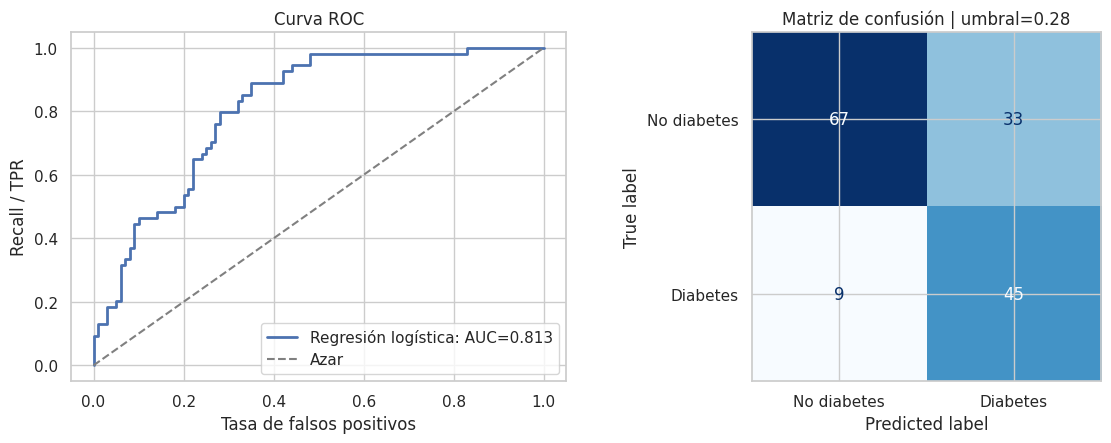

In [6]:
fig,axs=plt.subplots(1,2,figsize=(12,4.6))
fpr,tpr,_=roc_curve(y_test,prob)
axs[0].plot(fpr,tpr,label=f'{selected}: AUC={roc_auc_score(y_test,prob):.3f}',lw=2)
axs[0].plot([0,1],[0,1],'--',color='gray',label='Azar')
axs[0].set(xlabel='Tasa de falsos positivos',ylabel='Recall / TPR',title='Curva ROC');axs[0].legend()
ConfusionMatrixDisplay.from_predictions(y_test,predopt,labels=[0,1],display_labels=['No diabetes','Diabetes'],cmap='Blues',ax=axs[1],colorbar=False)
axs[1].set_title(f'Matriz de confusión | umbral={t:.2f}')
plt.tight_layout();plt.savefig(OUT/'roc_matriz.png',dpi=160);plt.show()

## 7. Experimento A/B pareado y significancia
**A:** umbral 0.50. **B:** umbral seleccionado mediante OOF. Ambos se prueban sobre los mismos individuos, por lo que no es una prueba A/B aleatorizada de despliegue. Se aplica McNemar exacto sobre aciertos discordantes; el p-valor es exploratorio y **no prueba superioridad clínica**. Como B fue elegido para favorecer recall, se examina también el cambio en FN y FP. Para un A/B real, asignar prospectivamente pacientes aleatoriamente a políticas A/B, con aprobación ética, métricas de seguridad y potencia calculada previamente.

In [7]:
# McNemar exacto mediante binomial de discordancias de acierto
correct_a=(pred05==y_test.to_numpy()); correct_b=(predopt==y_test.to_numpy())
a_only=int(np.sum(correct_a & ~correct_b))
b_only=int(np.sum(~correct_a & correct_b))
discordant=a_only+b_only
p_value=float(binomtest(min(a_only,b_only),n=discordant,p=.5,alternative='two-sided').pvalue) if discordant else 1.0
ab=pd.DataFrame([{'A':'Umbral 0.50','B':f'Umbral {t:.2f}','aciertos_solo_A':a_only,'aciertos_solo_B':b_only,
                  'discordantes':discordant,'p_mcnemar_exacto':p_value,'alpha':.05,'significativo':p_value<.05,
                  'delta_FN_B_menos_A':int(results.iloc[2].FN-results.iloc[1].FN),
                  'delta_FP_B_menos_A':int(results.iloc[2].FP-results.iloc[1].FP)}])
print(ab.to_string(index=False))
ab.to_csv(OUT/'experimento_ab.csv',index=False)
print('Interpretación:', 'Diferencia de exactitud estadísticamente detectable' if p_value<.05 else 'No se detecta diferencia de exactitud con alfa=0.05')

          A           B  aciertos_solo_A  aciertos_solo_B  discordantes  p_mcnemar_exacto  alpha  significativo  delta_FN_B_menos_A  delta_FP_B_menos_A
Umbral 0.50 Umbral 0.28               15               18            33          0.728332   0.05          False                 -18                  15
Interpretación: No se detecta diferencia de exactitud con alfa=0.05


## 8. Dashboard y registro de experimentos
El dashboard PNG presenta métricas, CV, curva ROC y matriz. Se exportan tablas CSV y un registro JSON con semilla, protocolo y parámetros. Los intervalos CV describen variación entre folds; no deben confundirse con intervalos de confianza independientes.

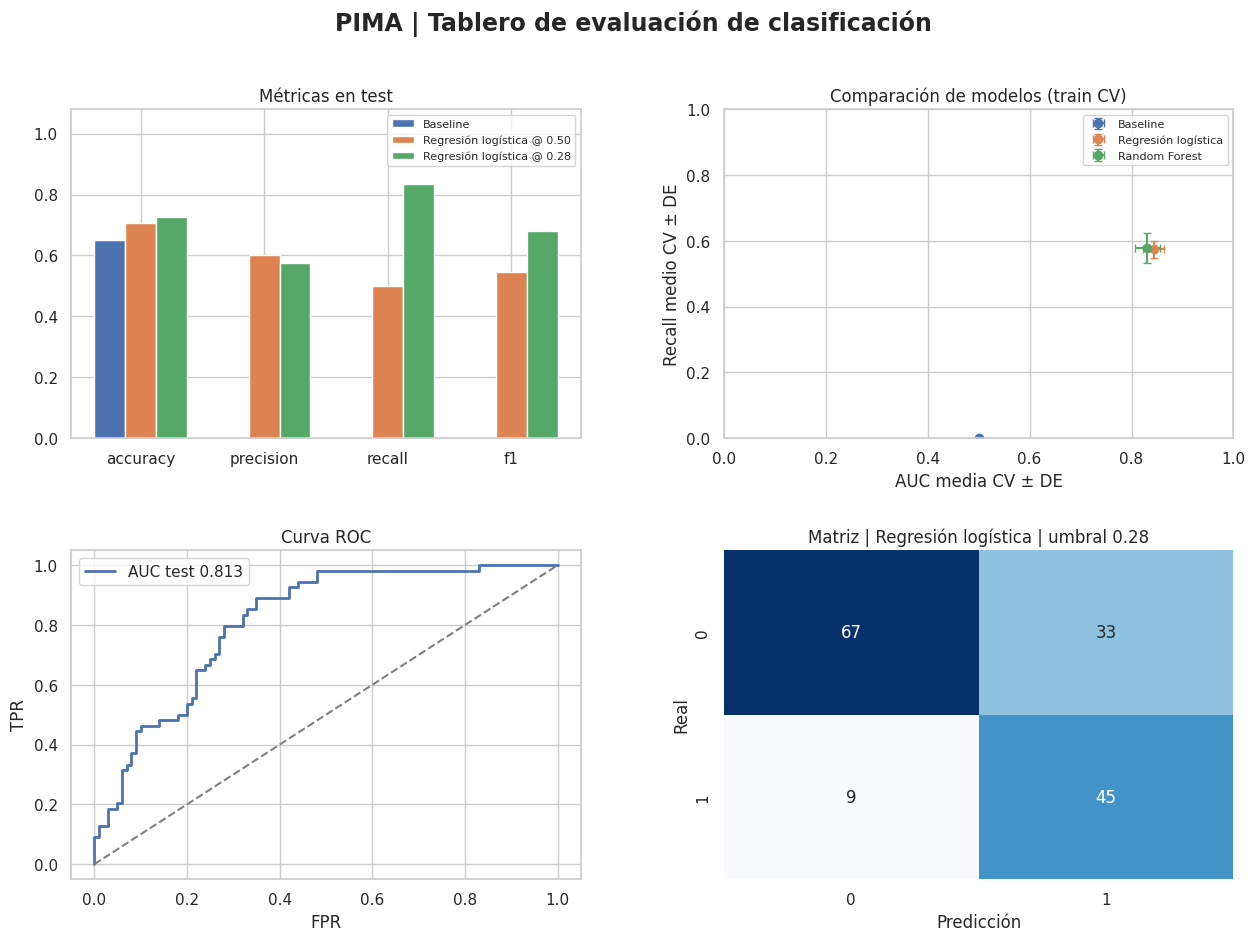

Archivos guardados en /content/resultados_pima


In [8]:
# Panel ejecutivo compacto, generado con resultados reales
fig=plt.figure(figsize=(15,10));gs=fig.add_gridspec(2,2,hspace=.34,wspace=.28)
ax=fig.add_subplot(gs[0,0]); metric_cols=['accuracy','precision','recall','f1']; x=np.arange(len(metric_cols)); w=.25
for i,(_,r) in enumerate(results.iterrows()):ax.bar(x+(i-1)*w,[r[c] for c in metric_cols],w,label=r.escenario)
ax.set_xticks(x,metric_cols);ax.set_ylim(0,1.08);ax.set_title('Métricas en test');ax.legend(fontsize=8)
ax=fig.add_subplot(gs[0,1]);
for _,r in cv_df.iterrows():ax.errorbar(r.auc_media,r.recall_media,xerr=r.auc_std,yerr=r.recall_std,fmt='o',capsize=3,label=r.modelo)
ax.set(xlim=(0,1),ylim=(0,1),xlabel='AUC media CV ± DE',ylabel='Recall medio CV ± DE',title='Comparación de modelos (train CV)');ax.legend(fontsize=8)
ax=fig.add_subplot(gs[1,0]);ax.plot(fpr,tpr,lw=2,label=f'AUC test {roc_auc_score(y_test,prob):.3f}');ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlabel='FPR',ylabel='TPR',title='Curva ROC');ax.legend()
ax=fig.add_subplot(gs[1,1]);sns.heatmap(confusion_matrix(y_test,predopt),annot=True,fmt='d',cmap='Blues',cbar=False,ax=ax)
ax.set(xlabel='Predicción',ylabel='Real',title=f'Matriz | {selected} | umbral {t:.2f}')
fig.suptitle('PIMA | Tablero de evaluación de clasificación',fontsize=17,fontweight='bold')
fig.savefig(OUT/'tablero_resultados.png',dpi=180,bbox_inches='tight');plt.show()
log={'dataset':source,'n_total':len(df),'n_train':len(y_train),'n_test':len(y_test),'seed':SEED,
     'split':'estratificado 80/20','cv':'StratifiedKFold 5 splits seed=42','modelo_seleccionado':selected,
     'criterio_modelo':'mayor AUC media CV, desempate recall','umbral':t,
     'criterio_umbral':'max precisión con recall OOF >= 0.80; fallback máximo F2',
     'resultado_test':results.iloc[2].to_dict(),'ab':ab.iloc[0].to_dict(),
     'limitaciones':['Dataset observacional y pequeño','No validación externa','A/B pareado offline, no aleatorizado','No uso clínico']}
(OUT/'registro_experimento.json').write_text(json.dumps(log,ensure_ascii=False,indent=2,default=lambda x: x.item() if hasattr(x,'item') else str(x)),encoding='utf-8')
print('Archivos guardados en',OUT.resolve())

## 9. Conclusiones y límites
- **Selección:** mayor AUC media CV entre candidatos, con desempate por recall; la comparación frente a baseline muestra si el aprendizaje aporta discriminación.
- **Umbral:** se decide solo con predicciones OOF de entrenamiento, priorizando sensibilidad. Se reporta el coste en falsos positivos.
- **Significancia:** McNemar exacto compara aciertos pareados A/B; un p valor ≥ 0.05 no prueba equivalencia.
- **Generalización:** CV estratificada ayuda a estimar estabilidad, pero falta validación externa y análisis de subgrupos, calibración, intervalos de confianza y deriva.
- **Advertencia:** el dataset contiene población específica y no es representativo de toda la población; ningún resultado debe usarse para diagnóstico clínico.